In [1]:
import os 
import functions
import mirdata
import librosa
import pandas as pd
import matplotlib.pyplot as plt
import mir_eval
import numpy as np
from tqdm import tqdm

In [2]:
ballroom = mirdata.initialize('ballroom')
# ballroom.download()
# ballroom.validate()
track_ids = ballroom.track_ids

c:\Users\jimea\OneDrive\Documents\QMUL\Sound and Music Computing\Term 2\Music Informatics\venv\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
c:\Users\jimea\OneDrive\Documents\QMUL\Sound and Music Computing\Term 2\Music Informatics\venv\lib\site-packages\google\api_core\_python_version_support.py:275: FutureWarning: You are using a Python version (3.10.11) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [3]:
# Split the prepared dataset into train and test sets (reproducible)
test_size = 0.3
seed = 42

track_ids_shuffled = track_ids.copy()
np.random.seed(seed)
np.random.shuffle(track_ids_shuffled)

split_idx = int(len(track_ids_shuffled) * (1 - test_size))
train_track_ids = track_ids_shuffled[:split_idx]
test_track_ids = track_ids_shuffled[split_idx:]

print(f"Train size: {len(train_track_ids)}")
print(f"Test size: {len(test_track_ids)}")

Train size: 488
Test size: 210


In [7]:
train_df_v2 = pd.DataFrame(columns=["track_name", "track_style", "bpm", "metre", "f1_score"])

alphas = [200, 300, 400, 500, 600, 700, 800, 900, 1000]
f1_score_mean = []

for alpha in alphas:
    for i, track_id in enumerate(tqdm(train_track_ids)):
        track = ballroom.track(track_id)
        split_path = track.audio_path.replace("\\", "/").split("/")
        track_name = split_path[-1]
        track_style = split_path[-2]
        metre = max(track.beats.positions)
        bpm = track.tempo
        estimated_beats, metre = functions.beats_simple(track.audio_path, alpha=alpha)
        f1_score = mir_eval.beat.f_measure(track.beats.times, estimated_beats)
        train_df_v2.loc[i] = [track_name, track_style, bpm, metre, f1_score]

    f1_score_mean.append(train_df_v2["f1_score"].mean())

100%|██████████| 488/488 [02:32<00:00,  3.20it/s]


In [10]:
np.round(f1_score_mean, 3)

array([0.735, 0.735, 0.736, 0.732, 0.732, 0.73 , 0.728, 0.722, 0.723])

In [12]:
alpha = 400

for i, track_id in enumerate(tqdm(train_track_ids)):
    track = ballroom.track(track_id)
    split_path = track.audio_path.replace("\\", "/").split("/")
    track_name = split_path[-1]
    track_style = split_path[-2]
    metre = max(track.beats.positions)
    bpm = track.tempo
    estimated_beats, metre = functions.beats_simple(track.audio_path, alpha=alpha)
    f1_score = mir_eval.beat.f_measure(track.beats.times, estimated_beats)
    train_df_v2.loc[i] = [track_name, track_style, bpm, metre, f1_score]

100%|██████████| 488/488 [02:20<00:00,  3.48it/s]


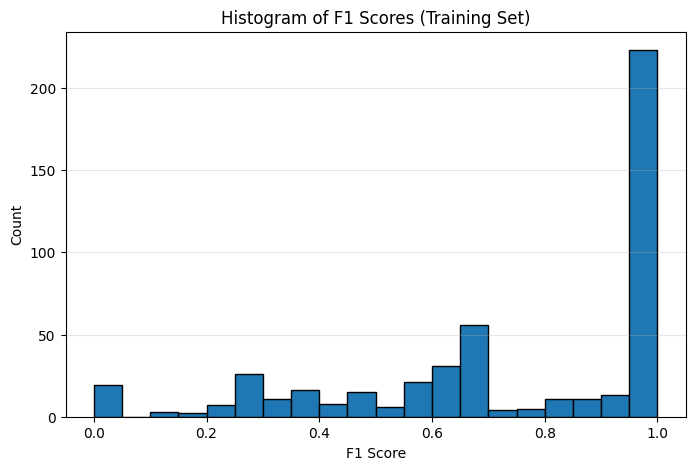

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(train_df_v2["f1_score"], bins=20, edgecolor="black")
plt.xlabel("F1 Score")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)
plt.show()